<a href="https://colab.research.google.com/github/profhamilton3/DataAnalytics/blob/main/session_notebooks/session_8_descriptive_statistics_profiling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 8: Descriptive Statistics & Profiling

**Course:** Data Analytics Foundation (CompTIA Data+) | **CompTIA Domain:** 3.0 Data Analysis

> Welcome to Session 8! Open this notebook in **Google Colab**. Descriptive statistics turn thousands of rows into a few numbers that describe *the typical value* and *how much values vary*. Tonight is also **Capstone Checkpoint 1**: the final part of this notebook is your profiling template.

### 🗺️ Your 45-Minute Lab Map
| Part | What you will do | Approx. time |
|---|---|---|
| Part 1 | Load the Boston Housing data; mean, median and mode of home values | 8 min |
| Part 2 | Variance and standard deviation in plain English | 6 min |
| Part 3 | Guided Example: the outlier effect, z-scores and comparing spread | 11 min |
| Part 4 | 🧩 Guided Challenge: neighborhood profiling + a sampling experiment | 12 min |
| Part 5 | ✏️ Capstone Checkpoint 1: profile your own dataset | 8 min (continues in the Block 5 sprint) |

**How to use this notebook:** read each text cell, then run the code cell beneath it with **Shift + Enter**.
Cells marked **✏️ Your Turn** have blanks (`___`) for you to fill in. Each one has a hidden solution
you can reveal *after* you have tried it. Errors are normal and part of learning. Read the last line
of the error message, fix it, and run the cell again.

In [16]:
# @title load the Boston Housing dataset by url
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"

housing = pd.read_csv(url)  # import data into a pandas DataFrame instance from a URL

print(housing.shape) # shows rows  and column count
housing.head()       # show first 5 rows

(506, 14)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [17]:
# @title some quick EDA
print("shape:",housing.shape)
print("columns\n",housing.columns)
display(housing.isna().sum())

shape: (506, 14)
columns
 Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'b', 'lstat', 'medv'],
      dtype='object')


,0
crim,0
zn,0
indus,0
chas,0
nox,0
rm,0
age,0
dis,0
rad,0
tax,0


**About the data:** 506 neighborhoods around Boston (1970s census). Key columns we will use:

| Column | Meaning |
|---|---|
| `medv` | **Median home value**, in **$1,000s** (so 24.0 = $24,000) |
| `rm` | Average number of rooms per home |
| `crim` | Crime rate per capita |
| `chas` | 1 if the neighborhood borders the Charles River, else 0 |
| `lstat` | % of lower-income residents |

## Part 1: Measures of Central Tendency, Finding the "Middle"

| Measure | Plain-English definition | Best used when |
|---|---|---|
| **Mean** | Add everything up and divide by the count: the "fair share" if everything were split evenly | Data is roughly symmetric, with no extreme outliers |
| **Median** | Line every value up in order and pick the one in the middle | Data is skewed or has outliers (salaries, home prices) |
| **Mode** | The value that shows up most often | Categories, or spotting repeated or "stuck" values |

In [19]:
# @title 	Median home value
medv = housing["medv"]

print("Mean home value:   $", round(medv.mean(), 2), "thousand")
print("Median home value: $", medv.median(), "thousand")
print("Mode home value:   $", medv.mode()[0], "thousand")

Mean home value:   $ 22.53 thousand
Median home value: $ 21.2 thousand
Mode home value:   $ 50.0 thousand


**🕵️ Something odd:** the most common value is exactly **50.0**, which is also the **maximum**. Let's count how many neighborhoods sit at exactly 50:

In [23]:
# @title  50 Thousand dollar hoods!
print("Neighborhoods with medv == 50:", (medv == 50).sum())

Neighborhoods with medv == 50: 16


Sixteen neighborhoods at exactly the top value is suspicious. This dataset was **capped** at $50,000, so any home worth more was recorded as 50. The **mode** just revealed a data-quality limitation (a *censored* variable). Always ask *why* a value repeats!

## Part 2: Variance and Standard Deviation in Plain English

Averages hide risk. Two neighborhoods can share the same average home value while one has homes from $10k to $50k and the other has every home near $22k.

- **Variance**: for each value, measure how far it is from the mean, square that distance (so negatives don't cancel positives), then average those squares. The result is in **squared units** ($1,000s²), which is hard to picture.
- **Standard deviation (std)**: the square root of the variance, which puts us back in normal units. Think of it as **"the typical distance from the average."**

**Low std** = values cluster tightly (consistent, predictable). **High std** = values are spread out (volatile, risky).

In [21]:
# @title Variance, STD, Range
print("Variance:          ", round(medv.var(), 2), "(thousand $)^2")
print("Standard deviation:", round(medv.std(), 2), "thousand $")
print("Range:             ", medv.min(), "to", medv.max())

Variance:           84.59 (thousand $)^2
Standard deviation: 9.2 thousand $
Range:              5.0 to 50.0


**💬 Interpretation:** a typical neighborhood's home value sits about **$9,200 away** from the average of about $22,500.

Now let's see the full profile in one command:

In [22]:
housing[["medv", "rm", "crim", "lstat"]].describe().round(2)

,medv,rm,crim,lstat
count,506.00,506.00,506.00,506.00
mean,22.53,6.28,3.61,12.65
std,9.20,0.70,8.60,7.14
min,5.00,3.56,0.01,1.73
25%,17.02,5.89,0.08,6.95
50%,21.20,6.21,0.26,11.36
75%,25.00,6.62,3.68,16.96
max,50.00,8.78,88.98,37.97


## Part 3: Guided Example: The Outlier Effect, Z-Scores and Comparing Spread

### Step 1: Watch one outlier wreck the mean
A small company has 9 employees. Calculate the mean and median salary.

In [24]:
# @title create our data using a pandas Series instance initalized with salaries
salaries = pd.Series([48_000, 52_000, 55_000, 58_000, 60_000, 61_000, 63_000, 67_000, 70_000])
print( "Mean:  ", round(salaries.mean()))
print("Median:", salaries.median())

Mean:   59333
Median: 60000.0


Now the CEO, who earns **$2,000,000**, joins the dataset. Predict what happens to each measure before you run the cell!

In [25]:
# @title Demonstrates distorted or skewed data
with_ceo = pd.concat([salaries, pd.Series([2_000_000])], ignore_index=True)

print("Mean:  ", round(with_ceo.mean()), "  <- jumped by about $190,000!")
print("Median:", with_ceo.median(), "  <- barely moved")

Mean:   253400   <- jumped by about $190,000!
Median: 60500.0   <- barely moved


**This is why news reports use *median* household income.** One extreme value dragged the mean far above what any typical employee earns.

### Step 2: Z-scores: "how unusual is this value?"
A **z-score** measures how many standard deviations a value sits from the mean:

$$z = \frac{\text{value} - \text{mean}}{\text{standard deviation}}$$

- z = 0 → exactly average · z = +2 → 2 std **above** average · z = −1.5 → 1.5 std **below**
- Rule of thumb: |z| > 2 is unusual; |z| > 3 is very rare.

In [26]:
# @title Z-Score in action with a new feature column `medv_z`

housing["medv_z"] = (housing["medv"] - housing["medv"].mean()) / housing["medv"].std() # adding a feature

unusual = housing[housing["medv_z"].abs() > 2] # create a new dataset filtering for medv_z > +2
print("Neighborhoods more than 2 std from the mean:", len(unusual))     # how many in the set
unusual[["medv", "medv_z", "rm", "crim"]].sort_values("medv_z").head(8).round(2)

Neighborhoods more than 2 std from the mean: 31


,medv,medv_z,rm,crim
157,41.3,2.04,6.94,1.22
232,41.7,2.08,8.34,0.58
202,42.3,2.15,7.61,0.02
253,42.8,2.20,8.26,0.37
261,43.1,2.24,7.52,0.53
268,43.5,2.28,7.47,0.54
98,43.8,2.31,7.82,0.08
256,44.0,2.33,7.45,0.02


### Step 3: Compare spread across columns with different units
Is crime rate more variable than room count? Their std values aren't comparable (different units!). The **coefficient of variation (CV)** = std ÷ mean expresses spread *relative to the average*.

In [27]:
# @title Spread realative to average using Coefficient of variation (CV)

for col in ["crim", "rm", "medv"]:
    cv = housing[col].std() / housing[col].mean()
    print(f"{col:5s}  mean={housing[col].mean():7.2f}  std={housing[col].std():6.2f}  CV={cv:5.2f}")

crim   mean=   3.61  std=  8.60  CV= 2.38
rm     mean=   6.28  std=  0.70  CV= 0.11
medv   mean=  22.53  std=  9.20  CV= 0.41


**💬 Insight:** room count is very consistent (CV ≈ 0.11), while crime is wildly uneven (CV ≈ 2.4). A few neighborhoods have extremely high crime. That also means the **mean** crime rate (3.6) is misleading compared with the **median** (0.26).

## Part 4: 🧩 Guided Challenge: Neighborhood Profiling for a Real-Estate Client

Your client asks: *"Do homes near the Charles River cost more, and how much do room counts matter?"* Answer with descriptive statistics, then run a sampling experiment.

**Step 1: River vs. non-river.** Group by `chas` and compute the count, mean, median and std of `medv`.

In [29]:
# @title  River vs. non-river. Group by chas and compute the count, mean, median and std of medv.

housing.groupby("chas")["medv"].agg(["count", "mean", "median", "std"]).round(2)

,count,mean,median,std
chas,,,,
0,471,22.09,20.9,8.83
1,35,28.44,23.3,11.82


<details>
<summary><b>💡 Reveal a possible solution</b> (try it yourself first!)</summary>

```python
housing.groupby("chas")["medv"].agg(["count", "mean", "median", "std"]).round(2)
```

</details>

**Step 2: Room-count bands.** Use `pd.cut()` to put `rm` into bands (`<5`, `5-6`, `6-7`, `7+`), then compare median home values by band.

In [30]:
# @title  Room-count bands. Use pd.cut()

housing["rooms_band"] = pd.cut(housing["rm"], bins=[0, 5, 6, 7, 9], labels=["<5", "5-6", "6-7", "7+"])

housing.groupby("rooms_band", observed=True)["medv"].agg(["count", "median", "std"]).round(2)

,count,median,std
rooms_band,,,
<5,16,13.80,10.61
5-6,157,18.60,5.31
6-7,269,22.20,6.47
7+,64,36.45,8.72


<details>
<summary><b>💡 Reveal a possible solution</b> (try it yourself first!)</summary>

```python
housing["rooms_band"] = pd.cut(housing["rm"], bins=[0, 5, 6, 7, 9], labels=["<5", "5-6", "6-7", "7+"])
housing.groupby("rooms_band", observed=True)["medv"].agg(["count", "median", "std"]).round(2)
```

</details>

**Step 3: A sampling experiment.** In real life we rarely see the whole **population**, only a **sample**. How close does a random sample of 30 neighborhoods get to the true mean?

- `.sample(n=30)` draws 30 random rows.
- Repeat it 200 times and keep each sample's mean.

In [32]:
# @title Sample comparison to Populaiton

population_mean = housing["medv"].mean()

sample_means = []       # creates and empty list with []
for i in range(200):   # for-loop using range function
    s = housing["medv"].sample(n=30, random_state=i)
    sample_means.append(s.mean())

sample_means = pd.Series(sample_means)
print("Population mean:          ", round(population_mean, 2))
print("Average of 200 sample means:", round(sample_means.mean(), 2))
print("Std of the sample means:   ", round(sample_means.std(), 2))

Population mean:           22.53
Average of 200 sample means: 22.55
Std of the sample means:    1.67


<details>
<summary><b>💡 Reveal a possible solution</b> (try it yourself first!)</summary>

```python
population_mean = housing["medv"].mean()
sample_means = []
for i in range(200):
    s = housing["medv"].sample(n=30, random_state=i)
    sample_means.append(s.mean())
sample_means = pd.Series(sample_means)
print("Population mean:          ", round(population_mean, 2))
print("Average of 200 sample means:", round(sample_means.mean(), 2))
print("Std of the sample means:   ", round(sample_means.std(), 2))
```

</details>

**Step 4: Plot the 200 sample means.** Compare the shape of this histogram with the skewed `medv` histogram.

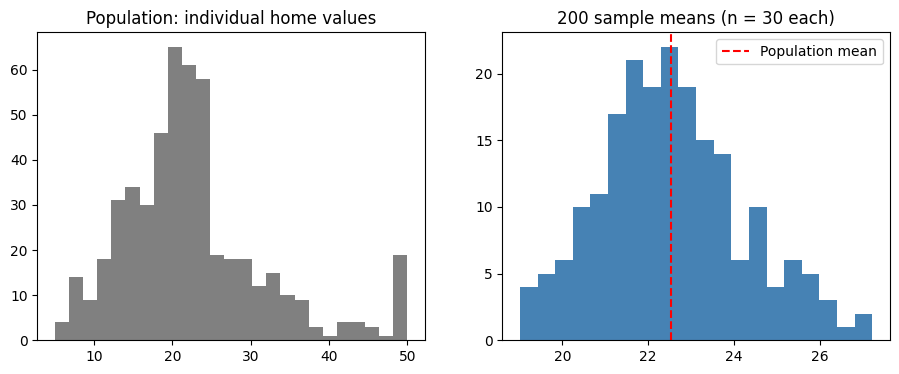

In [33]:
# @title Visualize the data spread -Plot the 200 sample means.

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(housing["medv"], bins=25, color="gray")
axes[0].set_title("Population: individual home values")
axes[1].hist(sample_means, bins=20, color="steelblue")
axes[1].axvline(population_mean, color="red", linestyle="--", label="Population mean")
axes[1].set_title("200 sample means (n = 30 each)")
axes[1].legend()
plt.show()

<details>
<summary><b>💡 Reveal a possible solution</b> (try it yourself first!)</summary>

```python
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(housing["medv"], bins=25, color="gray")
axes[0].set_title("Population: individual home values")
axes[1].hist(sample_means, bins=20, color="steelblue")
axes[1].axvline(population_mean, color="red", linestyle="--", label="Population mean")
axes[1].set_title("200 sample means (n = 30 each)")
axes[1].legend()
plt.show()
```

</details>

**✍️ Write a 3-sentence summary for the client** (double-click to edit): river premium, room-count effect, and what the sampling experiment tells you about trusting a sample.

<details>
<summary><b>💡 Reveal a sample answer</b></summary>

*Neighborhoods on the Charles River have a higher median home value (about $23,300 vs. $20,900) but also more variation, so the premium is real but not guaranteed. Room count matters even more: the median value roughly doubles from 5–6-room areas to 7+-room areas. Our sampling experiment shows that a random sample of just 30 neighborhoods usually lands within a couple of thousand dollars of the true mean, and the sample means form a symmetric bell shape even though home values are skewed. That bell shape (the Central Limit Theorem) is the foundation for the p-values and hypothesis tests we use next session.*

</details>

## Part 5: ✏️ Capstone Checkpoint 1: Profile Your Own Dataset

Use the template below on **your cleaned Capstone dataset**. Paste the output (or a screenshot) into your Checkpoint 1 submission.

**How to load your file:**
- **Option A, a URL:** paste a raw CSV link (for example a GitHub "Raw" link) into `capstone_url`.
- **Option B, upload from your computer:** run `from google.colab import files; files.upload()`, then use the file name, for example `pd.read_csv("my_data.csv")`.

*No dataset yet? Use the tips URL in the hint so you can still practice.*

In [35]:
# @title 1. LOAD your Capstone dataset
# using tips for the practice
# capstone_url = "PASTE_YOUR_CSV_URL_OR_FILENAME_HERE"
# hint (practice data): "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

capstone_url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(capstone_url)

# 2. SHAPE and DATA TYPES
print("Rows, columns:", df.shape)
df.info()

Rows, columns: (244, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


<details>
<summary><b>💡 Reveal a possible solution</b> (try it yourself first!)</summary>

```python
capstone_url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(capstone_url)
print("Rows, columns:", df.shape)
df.info()
```

</details>

In [36]:
# @title 3. EDA PROFILE: summary statistics for numeric columns
df.describe().round(2)

,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00


<details>
<summary><b>💡 Reveal a possible solution</b> (try it yourself first!)</summary>

```python
df.describe().round(2)
```

</details>

In [37]:
# @title 4. CATEGORICAL PROFILE + DATA QUALITY CHECKS
print(df.describe(exclude="number"))         # text columns: count, unique values, most frequent value
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

         sex smoker  day    time
count    244    244  244     244
unique     2      2    4       2
top     Male     No  Sat  Dinner
freq     157    151   87     176

Missing values per column:
 total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Duplicate rows: 1


<details>
<summary><b>💡 Reveal a possible solution</b> (try it yourself first!)</summary>

```python
print(df.describe(exclude="number"))
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
```

</details>

### 📝 Checkpoint 1 Reflection (double-click to fill in)
1. **Target metric:** which numeric column matters most to your business question? Mean ___, median ___, std ___.
2. **Skew check:** is the mean noticeably bigger or smaller than the median? What does that tell you?
3. **Outlier hunt:** which values look illogical (negative ages, a $0 price, a date in the future)? Your breakout partner should help you hunt.
4. **Next cleaning step:** what will you fix before Checkpoint 2?

---
## ✅ Lab Checklist
- [ ] Calculated mean, median and mode, and explained the suspicious mode of 50
- [ ] Calculated and interpreted variance and standard deviation
- [ ] Demonstrated the outlier effect and computed z-scores and CV
- [ ] Profiled neighborhoods by group and band and ran a sampling experiment
- [ ] Generated my Capstone EDA profile for Checkpoint 1

## 💾 Save Your Work to GitHub
1. In Colab, click **File → Save a copy in GitHub**.
2. Choose your course/Capstone repository.
3. Use this commit message: `Completed Session 8 Stats Lab and Checkpoint 1`

**Coming up next:** Session 9: moving from *describing* data to *proving* theories with t-tests, ANOVA and Chi-Square.